# M1 Assignment Solution
**Kapil Kumar Sharma**

**NET ID: apl25002**

**Date: 05-09-2026**


# Initialization and mounting to drive

In [2]:
# import modules

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set display options to show all columns
pd.set_option('display.max_columns', None)

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


# Task 1: Read in the dataset and determine how many rows and columns it has.

* First we read the csv 'Telco_customer_churn.csv' file.
* Then print the shape of the data frame, that shows number of rows and columns in dataset.

In [3]:
from google.colab import drive
df = pd.read_csv('/content/drive/MyDrive/Telco_customer_churn.csv')

df.shape

(7043, 33)

# Task 2: When you open a dataset Python will assume the data types for each column. What are the current continuous variables?

* Lets print variable datatypes in dataset.
* Then identify the continous variables

In [4]:
df.dtypes

,0
CustomerID,object
Count,int64
Country,object
State,object
City,object
Zip Code,int64
Lat Long,object
Latitude,float64
Longitude,float64
Gender,object


* Lets traverse thru the variable datatype list using for loop and add  condition int and float datatype (continous variable datatype)
* To filter data types, we can also use method 'select_dtypes'

In [5]:
for column in df.columns:
    if(df[column].dtype == "int64" or df[column].dtype == "float64"):
      print(column, df[column].dtype)

Count int64
Zip Code int64
Latitude float64
Longitude float64
Tenure Months int64
Monthly Charges float64
Churn Value int64
Churn Score int64
CLTV int64


* Variable 'Tenure Months' is separate from the year in its own standalone column, it is more categorical in nature than continuous.  Let's fix that.  

In [6]:
# Change 'Mfg_Month' from int64 to object
df['Tenure Months'] = df['Tenure Months'].astype(str)

# Verify the datatype change
print(df['Tenure Months'].dtypes)

# Display the head of the 'Mfg_Month' column to see the change
print(df['Tenure Months'].head())

object
0     2
1     2
2     8
3    28
4    49
Name: Tenure Months, dtype: object


In [7]:
temp_df = df.select_dtypes(include=["int64", "float64"])
print(temp_df.head())

   Count  Zip Code   Latitude   Longitude  Monthly Charges  Churn Value  \
0      1     90003  33.964131 -118.272783            53.85            1   
1      1     90005  34.059281 -118.307420            70.70            1   
2      1     90006  34.048013 -118.293953            99.65            1   
3      1     90010  34.062125 -118.315709           104.80            1   
4      1     90015  34.039224 -118.266293           103.70            1   

   Churn Score  CLTV  
0           86  3239  
1           67  2701  
2           86  5372  
3           84  5003  
4           89  5340  


* So, the Continous variable are: Latitude, Longitude, Monthly Charges, Churn Score (it is score in whole number but a type of measurement), CLTV
* 'Churn Value' is 0 and 1. It is Categorial type variable. But we have to convert it to object.

# Task 3: What are the current categorical variables?

* Wherever we see "object" or 'words in data' it is a categorical variable.

In [8]:
for column in df.columns:
    if(df[column].dtype == "object"):
      print(column, df[column].dtype)

CustomerID object
Country object
State object
City object
Lat Long object
Gender object
Senior Citizen object
Partner object
Dependents object
Tenure Months object
Phone Service object
Multiple Lines object
Internet Service object
Online Security object
Online Backup object
Device Protection object
Tech Support object
Streaming TV object
Streaming Movies object
Contract object
Paperless Billing object
Payment Method object
Total Charges object
Churn Label object
Churn Reason object


In [9]:
df.select_dtypes(include=["object"]).head()


,CustomerID,Country,State,City,Lat Long,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Total Charges,Churn Label,Churn Reason
0,3668-QPYBK,United States,California,Los Angeles,"33.964131, -118.272783",Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,108.15,Yes,Competitor made better offer
1,9237-HQITU,United States,California,Los Angeles,"34.059281, -118.30742",Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,151.65,Yes,Moved
2,9305-CDSKC,United States,California,Los Angeles,"34.048013, -118.293953",Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,820.5,Yes,Moved
3,7892-POOKP,United States,California,Los Angeles,"34.062125, -118.315709",Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,3046.05,Yes,Moved
4,0280-XJGEX,United States,California,Los Angeles,"34.039224, -118.266293",Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),5036.3,Yes,Competitor had better devices


* So the categorical variables are: CustomerID (Cateogorial/Nominal), Country, State, City, Gender, Senior Citizen, Partner, Dependents, Tenure Months, Phone Service, Multiple Lines, Internet Service, Online Security, Online Backup, Device Protection, Tech Support, Streaming TV, Steaming Movies, Contract, Paperless Billing, Payment Method, Churn Label
* Observation: 'Total Charges' are object and should be converted to Float datatype. And from the top head values, it seems a continuous variable. Will do it in following step.


# Task 4: Are there any columns that look like they might be the wrong data type?

* 'Total Charges' is in object and can be converted to Float. Lets do it now.
* 'Tenure_months'- already converted from int to object. In Task 2.

In [10]:
df['Total Charges'].head()

,Total Charges
0,108.15
1,151.65
2,820.5
3,3046.05
4,5036.3


* Changing 'Total Charges' datatype to Float.

In [11]:
# Change 'Total Charges' from object to float
df['Total Charges'] = pd.to_numeric(df['Total Charges'])

ValueError: Unable to parse string " " at position 2234

* Objervation: Conversion failed, due to some blank or missing data. Error: ValueError: Unable to parse string " " at position 2234.
* Action: Identify the number of blank rows for 'Total Charges' and fix it by placing 0 (int). And then we will try to parse it again.

In [12]:

#during conversion from object to float, got below error that gives us row number
#ValueError: Unable to parse string " " at position 2234
print(df.iloc[2234])


CustomerID                          4472-LVYGI
Count                                        1
Country                          United States
State                               California
City                            San Bernardino
Zip Code                                 92408
Lat Long                34.084909, -117.258107
Latitude                             34.084909
Longitude                          -117.258107
Gender                                  Female
Senior Citizen                              No
Partner                                    Yes
Dependents                                  No
Tenure Months                                0
Phone Service                               No
Multiple Lines                No phone service
Internet Service                           DSL
Online Security                            Yes
Online Backup                               No
Device Protection                          Yes
Tech Support                               Yes
Streaming TV 

In [13]:
#lets count the number of rows with total charges as blank
#df['Total Charges'].unique()
df['Total Charges'] = df['Total Charges'].str.strip()
blank_count = (df['Total Charges'] == '').sum()
print(blank_count)

11


In [14]:
#Fill this blank values with 0
df['Total Charges'] = df['Total Charges'].str.strip()
df.loc[df['Total Charges'] == '', 'Total Charges'] = '0'
print('blank replaced with value 0')

blank replaced with value 0


In [15]:
# Lets change the datatype from object to Float

# Change 'Total Charges' from object to float
df['Total Charges'] = pd.to_numeric(df['Total Charges'])

# Verify the datatype change
print(df['Total Charges'].dtypes)

# Display the head of the 'Mfg_Month' column to see the change
print(df['Total Charges'].head())

float64
0     108.15
1     151.65
2     820.50
3    3046.05
4    5036.30
Name: Total Charges, dtype: float64


# Task 5: Build a bar chart to show average Monthly Charges by Churn Label. How do the monthly changes compare for those who churn and those who do not?

* Lets build bar chart to show average Monthly Charges by Churn Label.

In [16]:
df.head()
print(df[['Monthly Charges', 'Churn Value']])

      Monthly Charges  Churn Value
0               53.85            1
1               70.70            1
2               99.65            1
3              104.80            1
4              103.70            1
...               ...          ...
7038            21.15            0
7039            84.80            0
7040           103.20            0
7041            29.60            0
7042           105.65            0

[7043 rows x 2 columns]


Since the 'Churn Value' data is all 0s and 1s, but it is int datatype, let's change the data type to Object for 'Churn Value'

In [17]:
# Change 'Churn Value' from int64 to object
df['Churn Value'] = df['Churn Value'].astype(str)

# Verify the datatype change
print(df['Churn Value'].dtypes)

# Optional: Display the head of the 'Churn Value' column to see the change
print(df['Churn Value'].head())

object
0    1
1    1
2    1
3    1
4    1
Name: Churn Value, dtype: object


In [18]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes,1,89,5340,Competitor had better devices


In [19]:
df.dtypes

,0
CustomerID,object
Count,int64
Country,object
State,object
City,object
Zip Code,int64
Lat Long,object
Latitude,float64
Longitude,float64
Gender,object


Similar 0/1 kind datatype column is 'Count'. Lets convert 'Count' datatype also from int to Object.

In [20]:
# Change 'Count' from int64 to object
df['Count'] = df['Count'].astype(str)

# Verify the datatype change
print(df['Count'].dtypes)

# Optional: Display the head of the 'Count' column to see the change
print(df['Count'].head())

object
0    1
1    1
2    1
3    1
4    1
Name: Count, dtype: object


Now let's do a final check of our data types.

In [21]:
for column in df.columns:
    print(column, df[column].dtype)

CustomerID object
Count object
Country object
State object
City object
Zip Code int64
Lat Long object
Latitude float64
Longitude float64
Gender object
Senior Citizen object
Partner object
Dependents object
Tenure Months object
Phone Service object
Multiple Lines object
Internet Service object
Online Security object
Online Backup object
Device Protection object
Tech Support object
Streaming TV object
Streaming Movies object
Contract object
Paperless Billing object
Payment Method object
Monthly Charges float64
Total Charges float64
Churn Label object
Churn Value object
Churn Score int64
CLTV int64
Churn Reason object


Looks good!

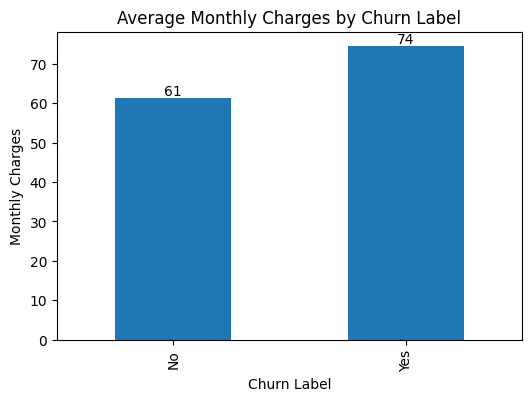

In [22]:
# Bar chart of average car price by Churn Label
plt.figure(figsize=(6,4))
ax = df.groupby('Churn Label')['Monthly Charges'].mean().plot(kind='bar')
plt.title('Average Monthly Charges by Churn Label')
plt.xlabel('Churn Label')
plt.ylabel('Monthly Charges')

# Add labels to the bars
# adds the actual average monthly charge values
# on top of each bar for easy interpretation.
ax.bar_label(ax.containers[0], fmt='{:,.0f}')

plt.show()

* The bar chart indicates that customers who churned tend to have higher monthly charges, whereas customers who did not churn generally have lower average monthly charges.

# Task 6: Build a histogram of Monthly Charges. Describe some features of the distribution.

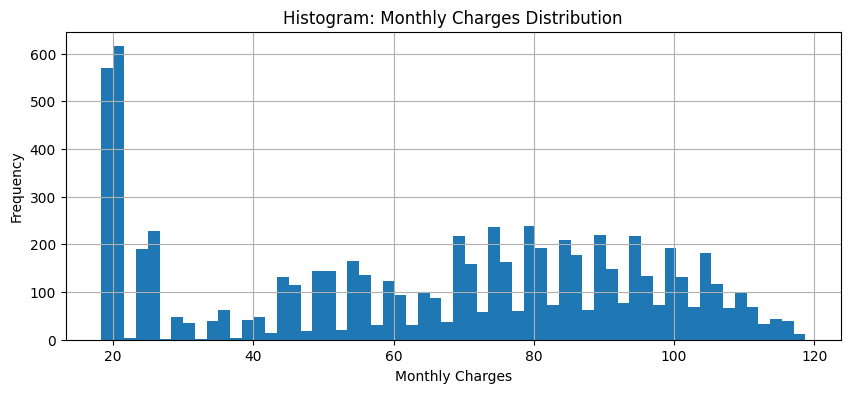

In [23]:
# Histogram of Monthly Charges
plt.figure(figsize=(10,4))
df['Monthly Charges'].hist(bins=60)
plt.title('Histogram: Monthly Charges Distribution')
plt.xlabel('Monthly Charges')
plt.ylabel('Frequency') # Added y-axis label for clarity
plt.show()

* Feature of 'Monthly Charges' distribution:
1. The most common monthly charge is around 20, with a frequency of 550 to 610  customers.
2. Monthly charges in the range of 70 to 110 are also relatively common, with a frequency of around 200 customers in each breakup.

# Task 7: Make comparative boxplots for Tenure Months by Churn Label and Monthly Charges by Churn Label.

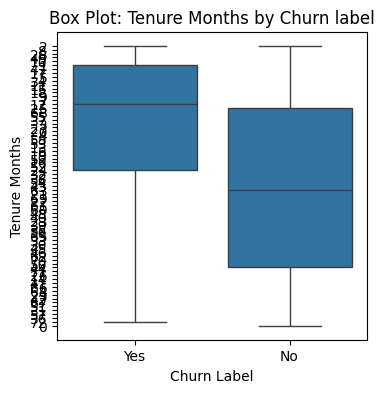

In [24]:
# Box Plot: Tenure Months
plt.figure(figsize=(4,4))
sns.boxplot(data=df, x='Churn Label', y='Tenure Months')
plt.title('Box Plot: Tenure Months by Churn label')
plt.ylabel('Tenure Months')
plt.show()

The character on Y axis is due to the datatype of 'Tenure Months' that I have converted to Object. And the boxplot also looks incorrect.
* Lets rollback 'Tenure Months' object datatype to int datatype and run the boxplot again.

In [25]:
df['Tenure Months'] = pd.to_numeric(
    df['Tenure Months'].astype(str).str.strip(),
    errors='coerce'
)

In [26]:
print(df['Tenure Months'].dtype)

int64


1. BoxPlot for Tenure Months by Churn Label

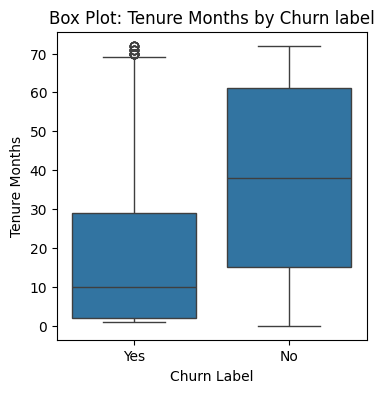

In [27]:
# Box Plot: Tenure Months
plt.figure(figsize=(4,4))
sns.boxplot(data=df, x='Churn Label', y='Tenure Months')
plt.title('Box Plot: Tenure Months by Churn label')
plt.ylabel('Tenure Months')
plt.show()

2. Boxplot for Monthly Charges by Churn Label

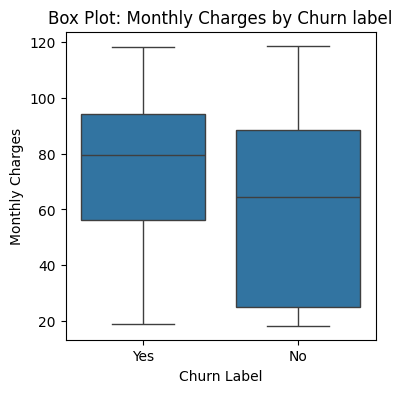

In [28]:
# Box Plot: Tenure Months
plt.figure(figsize=(4,4))
sns.boxplot(data=df, x='Churn Label', y='Monthly Charges')
plt.title('Box Plot: Monthly Charges by Churn label')
plt.ylabel('Monthly Charges')
plt.show()

* Comparative boxplots. Lets put both box plot together

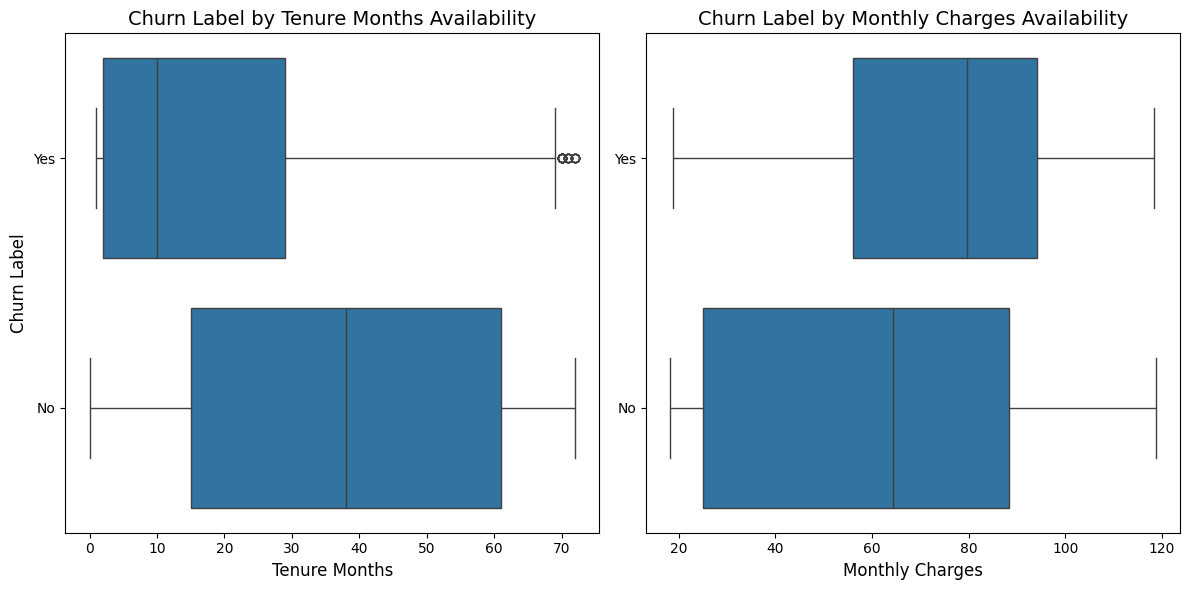

In [29]:
# Box Plots: 'Churn Label' by 'Tenure Months' and 'Monthly Charges'
plt.figure(figsize=(12, 6)) # Adjust figure width for two plots

# Box Plot for Churn Label by Tenure Months
plt.subplot(1, 2, 1) # Create a 1x2 grid of plots and select the 1st subplot
sns.boxplot(data=df, x='Tenure Months', y='Churn Label')
plt.title('Churn Label by Tenure Months Availability', fontsize=14) # Increase title font size
plt.xlabel('Tenure Months', fontsize=12) # Increase xlabel font size
plt.ylabel('Churn Label', fontsize=12) # Keep ylabel for the first plot

# Box Plot for Churn Label by Monthly Charges
plt.subplot(1, 2, 2) # Select the 2nd subplot
sns.boxplot(data=df, x='Monthly Charges', y='Churn Label')
plt.title('Churn Label by Monthly Charges Availability', fontsize=14) # Increase title font size
plt.xlabel('Monthly Charges', fontsize=12) # Increase xlabel font size
plt.ylabel('', fontsize=12) # Leave ylabel empty for the second plot

plt.tight_layout()
plt.show()

# Task 8: Comment on what you see about Tenure Months and Monthly Charges as possible predictors of churn.

* We already made boxplots for both 'Tenure Months by Churn label' and 'Monthly Charges by Churn label'.


Comment:


1.   The box plot gives us better insight for Tenure months with churn labelled out or not. Compared to just a simple bar chart.
2.   When comparing the potential predictors, Tenure Months appears to be a stronger predictor of Churn Label than Monthly Charges.



 # Task 9: Check the correlations of the continuous variables.

In [30]:
# Correlations
# Select only the continuous variables
continuous_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Create the correlation table
correlation_table = df[continuous_cols].corr()

# Display the correlation table with color
print("Correlation Table of Continuous Variables:")
display(correlation_table.style.background_gradient(cmap='coolwarm', axis=None))

Correlation Table of Continuous Variables:


,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Total Charges,Churn Score,CLTV
Zip Code,1.000000,0.895743,-0.784271,0.001041,-0.004596,-0.000884,-0.002769,-0.003562
Latitude,0.895743,1.000000,-0.876779,-0.001631,-0.019899,-0.009944,-0.007684,0.000886
Longitude,-0.784271,-0.876779,1.000000,-0.001678,0.024098,0.008876,0.004260,0.000485
Tenure Months,0.001041,-0.001631,-0.001678,1.000000,0.247900,0.826178,-0.224987,0.396406
Monthly Charges,-0.004596,-0.019899,0.024098,0.247900,1.000000,0.651174,0.133754,0.098693
Total Charges,-0.000884,-0.009944,0.008876,0.826178,0.651174,1.000000,-0.123410,0.342091
Churn Score,-0.002769,-0.007684,0.004260,-0.224987,0.133754,-0.123410,1.000000,-0.079782
CLTV,-0.003562,0.000886,0.000485,0.396406,0.098693,0.342091,-0.079782,1.000000


Looks like Zip code have strong negative correlation with Latitude (0.895743) and also Tenure Months with Total Charges (0.826178).


Whereas Latitute and Longitude have Strong correlation in between (-0.876779). Also 'Tenure Months' have strong correlation with 'Churn Score' (-0.224987).

# 10. Check for missing values. What did you find?

Let's check the dataset for missing values.

In [31]:
# Check for missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

# Check the total number of missing values in the DataFrame
print("\nTotal missing values in the dataset:")
print(df.isnull().sum().sum())

Missing values per column:
CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

Total missing values in the dataset:
5174


In [32]:
df.shape

(7043, 33)

All columns look good! Except 'Churn Reason' with almost 75% times (5174/7043)  its value is null!

#Task 11. Check for outliers in each of the continuous variables. Do any of them have outliers?

Next let's check for any very extreme values.  Here are two ways to do this.  

First, let's look do some math to use the quantile range approach.
And will use the same approach to check all the continuous columns.

In [33]:
## Detecting Outliers in All Numeric Columns

# Select only the numeric columns
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Iterate through each numeric column to find outliers
for col in numeric_cols:
    print(f"Checking for outliers in column: {col}")

    # calculate interquartile range (IQR)
    q1 = df[col].quantile(0.1)
    q3 = df[col].quantile(0.9)
    iqr = q3 - q1

    # define the boundaries for an outlier
    lower_bound = q1 - (3 * iqr)
    upper_bound = q3 + (3 * iqr)

    # find the outliers
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    # display the outliers for the current column
    if not outliers.empty:
        print(f"Outliers found in {col}: {len(outliers)} outliers")
        # Display only the outlier values from the current column
        print(outliers[col])
    else:
        print(f"No outliers found in {col} using the quantile range method.")
    print("-" * 30) # Separator for clarity between columns

Checking for outliers in column: Zip Code
No outliers found in Zip Code using the quantile range method.
------------------------------
Checking for outliers in column: Latitude
No outliers found in Latitude using the quantile range method.
------------------------------
Checking for outliers in column: Longitude
No outliers found in Longitude using the quantile range method.
------------------------------
Checking for outliers in column: Tenure Months
No outliers found in Tenure Months using the quantile range method.
------------------------------
Checking for outliers in column: Monthly Charges
No outliers found in Monthly Charges using the quantile range method.
------------------------------
Checking for outliers in column: Total Charges
No outliers found in Total Charges using the quantile range method.
------------------------------
Checking for outliers in column: Churn Score
No outliers found in Churn Score using the quantile range method.
------------------------------
Checki

* So we do not have any outliers in Continous variables.

# Task 12. Check for row outliers using Mahalanobis distance. What did you find?

* Find outliers using Mahalanobis Distance, considering an entire row of data rather than one column at a time.

In [34]:
print(df.select_dtypes(include=['int64', 'float64']).columns)

df.head()

Index(['Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges',
       'Total Charges', 'Churn Score', 'CLTV'],
      dtype='object')


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes,1,89,5340,Competitor had better devices


     Count        Country       State           City  Zip Code  \
424      1  United States  California    Davis Creek     96108   
425      1  United States  California   Fort Bidwell     96112   
426      1  United States  California      Lake City     96115   
853      1  United States  California     Eagleville     96110   
854      1  United States  California   Fort Bidwell     96112   
855      1  United States  California      Lake City     96115   
1206     1  United States  California  Mckinleyville     95519   
1288     1  United States  California      Lake City     96115   
1407     1  United States  California     Parker Dam     92267   
3059     1  United States  California     Cedarville     96104   
3064     1  United States  California     Eagleville     96110   
3376     1  United States  California           Earp     92242   
4283     1  United States  California     Cedarville     96104   
4287     1  United States  California    Davis Creek     96108   
5498     1

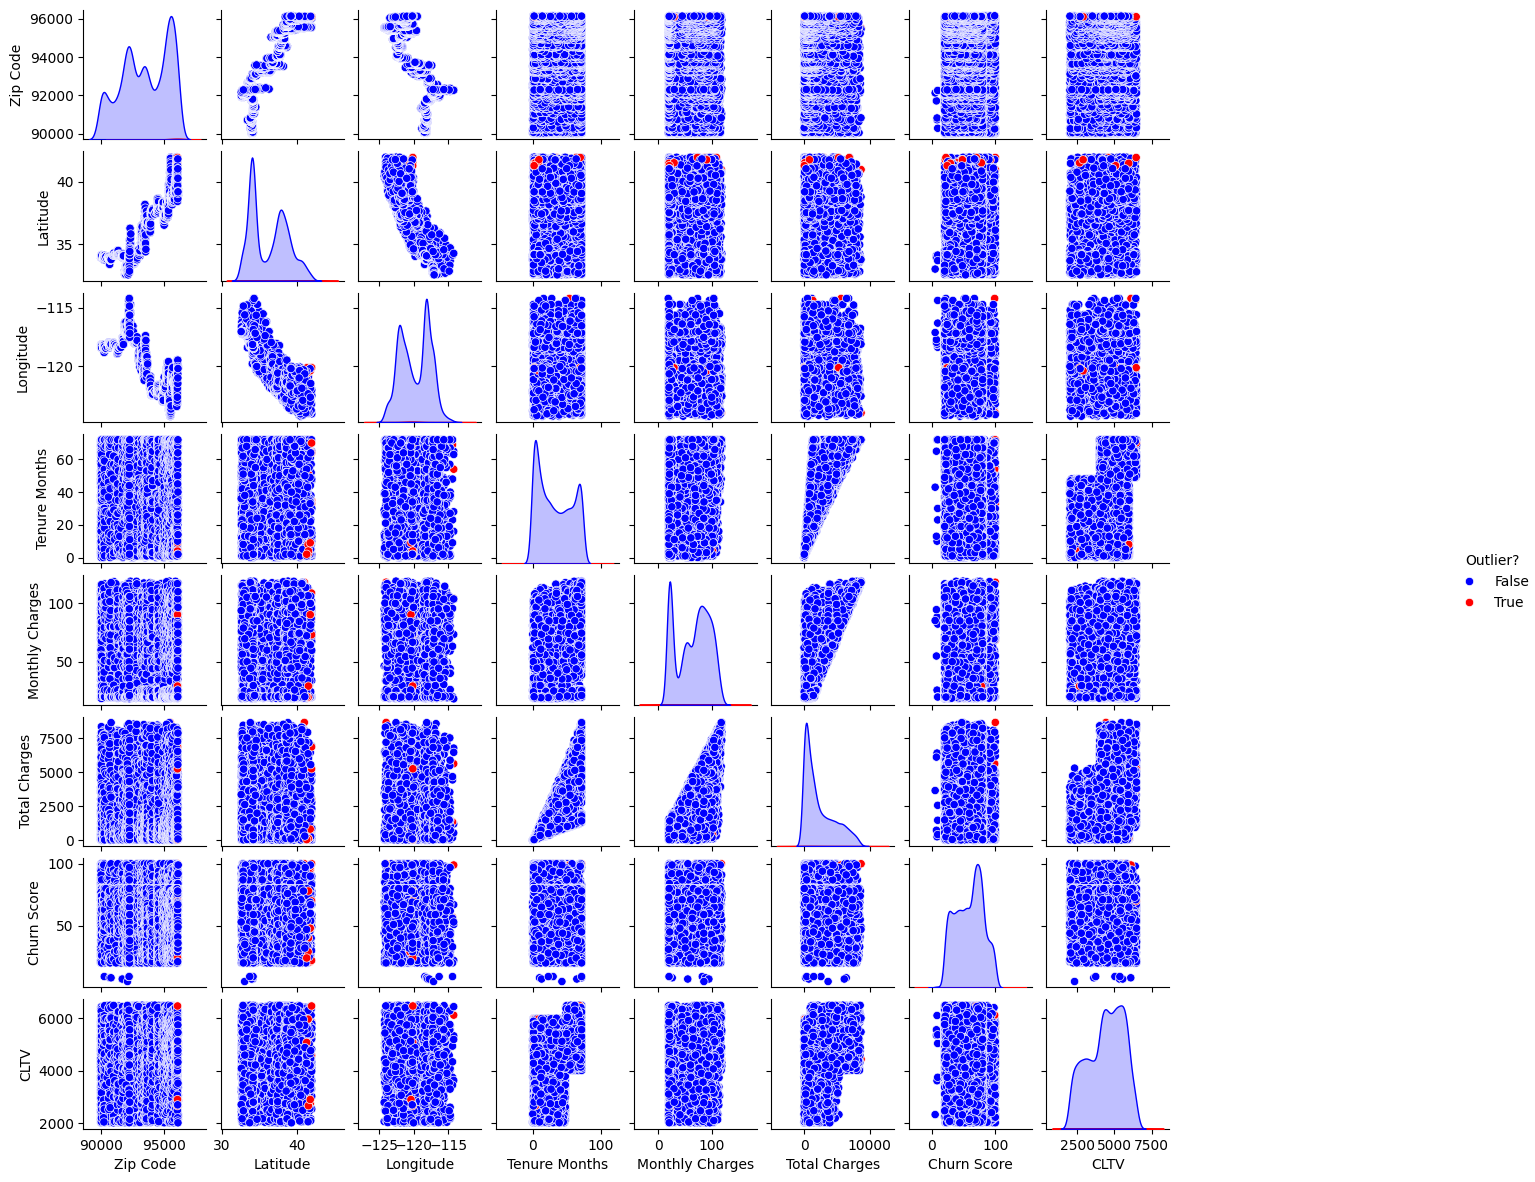

In [35]:
import pandas as pd
from scipy.spatial.distance import mahalanobis

# Remove the 'Id' column as it is an identifier and not useful for distance calculation
if 'CustomerID' in df.columns:
    df = df.drop('CustomerID', axis=1)

# subset the DataFrame to only include columns with numeric data
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
#df = df[numeric_cols]
df_numeric = df[numeric_cols].copy() # Create a copy to avoid modifying the original df

# Handle Missing Values using Mean Imputation
for col in df_numeric.columns:
    if df_numeric[col].isnull().any():
        mean_val = df_numeric[col].mean()
        df_numeric[col] = df_numeric[col].fillna(mean_val)

# calculate Mahalanobis distance for each row
cov = df_numeric.cov()
inv_cov = pd.DataFrame(np.linalg.inv(cov.values), index=cov.index, columns=cov.columns)
mean = df_numeric.mean()
distances = []
for i, row in df_numeric.iterrows():
    distances.append(mahalanobis(row, mean, inv_cov))

# calculate threshold for outliers (can be adjusted to suit your needs)
threshold = np.mean(distances) * 1.7

# create new column in DataFrame to flag outliers
df['is_outlier'] = pd.Series([dist > threshold for dist in distances], index=df_numeric.index)

# print rows that are flagged as outliers
print(df[df['is_outlier']])

# create a scatterplot matrix of the numeric columns and color the points based on is_outlier
g = sns.pairplot(df, height=1.5, hue='is_outlier', palette=['blue', 'red'])

# remove the legend title and adjust the legend position
g._legend.set_title('Outlier?')
g._legend.set_bbox_to_anchor([1.2, 0.5])

# show the plot
plt.show()


22 rows were identified as outliers.  The associated points for those rows are shown in red above.

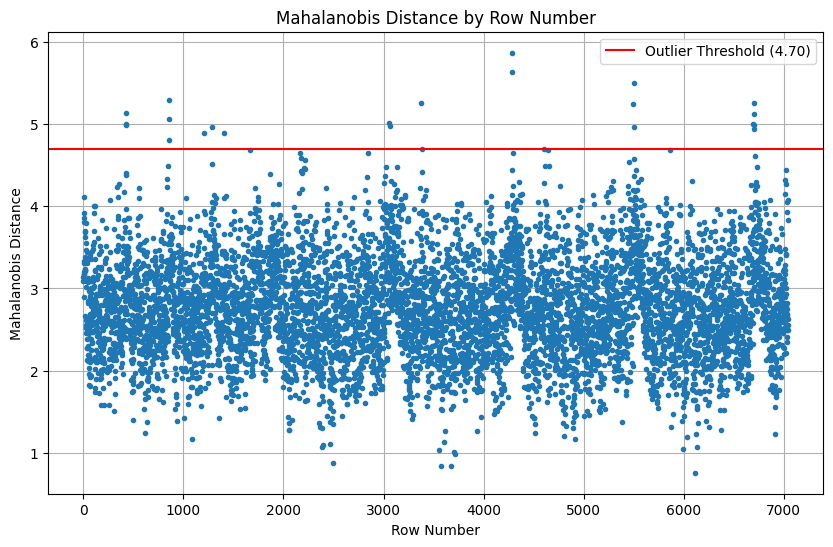

In [36]:
# Plot Mahalanobis distances
plt.figure(figsize=(10, 6))
# Use df.index as the x-axis since distances correspond to the original DataFrame rows
plt.plot(df_numeric.index, distances, marker='o', linestyle='', markersize=3)
plt.axhline(y=threshold, color='r', linestyle='-', label=f'Outlier Threshold ({threshold:.2f})')
plt.title('Mahalanobis Distance by Row Number')
plt.xlabel('Row Number')
plt.ylabel('Mahalanobis Distance')
plt.legend()
plt.grid(True)
plt.show()

The visualization shows the distance for each row.
A larger distance indicates that a row is more different from the rest of the dataset.

* The points above the threshold line correspond to the same 22 rows identified in the previous step.